# 1. Dataset Information


Title: **NCHS - Leading Causes of Death: United States** <br>
Source: https://data.cdc.gov/National-Center-for-Health-Statistics/NCHS-Leading-Causes-of-Death-United-States/bi63-dtpu/about_data <br>

Real world context: <br>

This data set can be used to analyze and summarize the leading causes of death in the United States in recent years. It can be used to evaluate key weaknesses in disease prevention and healthcare systems and formulate policies to tackle them.


# 2. Basic Data Exploration

In [133]:
import pandas as pd


#set float format to not have exponents 
pd.options.display.float_format = '{:.2f}'.format

data = pd.read_csv('dataset.csv')
data.head()


,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate
0,2012,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,21,2.6
1,2017,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,29,3.3
2,2016,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,30,3.7
3,2013,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,30,3.8
4,2000,"Intentional self-harm (suicide) (*U03,X60-X84,...",Suicide,District of Columbia,23,3.8


In [134]:
data.tail()

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate
10863,2001,All Causes,All causes,District of Columbia,"5,951","1,049.9"
10864,2002,All Causes,All causes,Mississippi,"28,853","1,051.6"
10865,2000,All Causes,All causes,Mississippi,"28,654","1,051.9"
10866,2000,All Causes,All causes,District of Columbia,"6,001","1,061.2"
10867,1999,All Causes,All causes,District of Columbia,"6,076","1,087.3"


In [135]:
data

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate
0,2012,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,21,2.6
1,2017,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,29,3.3
2,2016,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,30,3.7
3,2013,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,30,3.8
4,2000,"Intentional self-harm (suicide) (*U03,X60-X84,...",Suicide,District of Columbia,23,3.8
...,...,...,...,...,...,...
10863,2001,All Causes,All causes,District of Columbia,"5,951","1,049.9"
10864,2002,All Causes,All causes,Mississippi,"28,853","1,051.6"
10865,2000,All Causes,All causes,Mississippi,"28,654","1,051.9"
10866,2000,All Causes,All causes,District of Columbia,"6,001","1,061.2"


**Rows**: 10868
**Columns**: 6

In [136]:
print(data.columns.tolist())

['Year', '113 Cause Name', 'Cause Name', 'State', 'Deaths', 'Age-adjusted Death Rate']


**The Column Names are** : Year, 113 Cause Name, Cause Name, State, Deaths and Age-adjusted Death Rate

# 3. Data Types and Structure

In [137]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10868 entries, 0 to 10867
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Year                     10868 non-null  int64
 1   113 Cause Name           10868 non-null  str  
 2   Cause Name               10868 non-null  str  
 3   State                    10868 non-null  str  
 4   Deaths                   10868 non-null  str  
 5   Age-adjusted Death Rate  10868 non-null  str  
dtypes: int64(1), str(5)
memory usage: 509.6 KB


In [138]:
categories = data.select_dtypes(include=['object', 'category'],exclude=['str']).columns

print(categories)

Index([], dtype='str')


### Numerical 
Year
### Categorial / Object 
None
### String
113 Cause Name, Cause Name, State, Deaths, Age-adjusted Death Rate

### Which Datatype should be converted ? 
I think the Deaths and Age-adjusted Death Rate columns should be converted to numeric. <br>
Death should be converted to an integer. <br>
Age-adjusted death rate should be converted to floating point value type.

This is because, number of deaths cannot be in decimal values, and age-adjusted death rate would better be analyzed as a numeric column.

# 4. Descriptive Summary

In [139]:
data.describe(include='all')

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate
count,10868.00,10868,10868,10868,10868,10868
unique,NaN,11,11,52,5964,2490
top,NaN,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,343,19.2
freq,NaN,988,988,209,15,40
mean,2008.00,NaN,NaN,NaN,NaN,NaN
std,5.48,NaN,NaN,NaN,NaN,NaN
min,1999.00,NaN,NaN,NaN,NaN,NaN
25%,2003.00,NaN,NaN,NaN,NaN,NaN
50%,2008.00,NaN,NaN,NaN,NaN,NaN
75%,2013.00,NaN,NaN,NaN,NaN,NaN


For now, the only numerical column is Year. <br>
Here, min and max tell us the oldest and latest data we have. <br>
We have min of 1999 so the oldest available data is from 1999, and we have a max of 2017, so the latest available data is from 2017.

# 5. Missing or Duplicated Data

In [140]:
data.isna().sum()

Year                       0
113 Cause Name             0
Cause Name                 0
State                      0
Deaths                     0
Age-adjusted Death Rate    0
dtype: int64

There are no missing values in any column


In [141]:
data.duplicated().any()

np.False_

There are no duplicates.

# Let's convert the columns first

In [142]:
data['Deaths'] = data['Deaths'].str.replace(',', '').astype('int64')

In [143]:
data['Age-adjusted Death Rate'] = data['Age-adjusted Death Rate'].str.replace(',', '').astype('float64')

In [144]:
data.info() 

<class 'pandas.DataFrame'>
RangeIndex: 10868 entries, 0 to 10867
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Year                     10868 non-null  int64  
 1   113 Cause Name           10868 non-null  str    
 2   Cause Name               10868 non-null  str    
 3   State                    10868 non-null  str    
 4   Deaths                   10868 non-null  int64  
 5   Age-adjusted Death Rate  10868 non-null  float64
dtypes: float64(1), int64(2), str(3)
memory usage: 509.6 KB


Now that we've converted coulmns to numeric, let's get the summary again.

In [145]:
data.describe() # we're describing only numeric columns

,Year,Deaths,Age-adjusted Death Rate
count,10868.00,10868.00,10868.00
mean,2008.00,15459.91,127.56
std,5.48,112876.02,223.64
min,1999.00,21.00,2.60
25%,2003.00,612.00,19.20
50%,2008.00,1718.50,35.90
75%,2013.00,5756.50,151.72
max,2017.00,2813503.00,1087.30


# 6. Filter the Data

Here, we can see that the mean death is shown as 15459, which is largely influenced by the 'All Causes' category , containing the sum of deaths caused by all diseases in that particular year, in that particular state. So, firstly we have to filter the data to exclude all causes.

In [146]:
exclude_all = data[data['Cause Name'] != 'All causes']

In [147]:
exclude_all

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate
0,2012,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,21,2.60
1,2017,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,29,3.30
2,2016,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,30,3.70
3,2013,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,30,3.80
4,2000,"Intentional self-harm (suicide) (*U03,X60-X84,...",Suicide,District of Columbia,23,3.80
...,...,...,...,...,...,...
9875,1999,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,West Virginia,6822,325.50
9876,2002,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,Mississippi,9061,332.60
9877,2001,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,Mississippi,9050,333.50
9878,2000,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,Mississippi,9256,341.20


Now, let's summarize the dataset, yet again.

In [148]:
exclude_all.describe()

,Year,Deaths,Age-adjusted Death Rate
count,9880.00,9880.00,9880.00
mean,2008.00,7344.25,60.46
std,5.48,39732.34,67.31
min,1999.00,21.00,2.60
25%,2003.00,554.00,18.27
50%,2008.00,1453.50,31.45
75%,2013.00,3474.75,54.90
max,2017.00,725192.00,347.40


In [149]:
exclude_all[exclude_all['Deaths'] == exclude_all['Deaths'].max()]

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate
9793,1999,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,United States,725192,266.50


Now, if we want to know the highest number of deaths caused by individual disease, in an individual state, we need to exclude united states.

In [150]:
exclude_states_exclude_all = exclude_all[exclude_all['State'] != 'United States']

exclude_states_exclude_all[exclude_states_exclude_all['Deaths'] == exclude_states_exclude_all['Deaths'].max()]

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate
9768,1999,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,California,71930,257.30


So, the highest number of deaths, in a year, caused by a single disease was in 1999. 

### Second Filter

Let us now only include only all causes death in our next filter

In [151]:
include_all = data[data['Cause Name'] == 'All causes']

In [152]:
include_all.describe()

,Year,Deaths,Age-adjusted Death Rate
count,988.00,988.00,988.00
mean,2008.00,96616.54,798.63
std,5.48,342383.83,97.20
min,1999.00,2708.00,572.00
25%,2003.00,13421.75,724.55
50%,2008.00,37403.00,784.45
75%,2013.00,60584.75,865.30
max,2017.00,2813503.00,1087.30


Let us try to exclude data whose value in the state column is 'United States' and only consider values of individual US states.

In [153]:
exclude_states_include_all = include_all[include_all['State'] != 'United States']

In [154]:
exclude_states_include_all[exclude_states_include_all['Deaths'] == exclude_states_include_all['Deaths'].max()]

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate
9891,2017,All Causes,All causes,California,268189,618.70


Here, now we can conclude that the highest number of deaths recorded was in california in 2017.

# 7. Add a New Column Using Existing Columns

Let us now use the filtered data set for our new operation

In [155]:
exclude_states_exclude_all

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate
0,2012,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,21,2.60
1,2017,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,29,3.30
2,2016,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,30,3.70
3,2013,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,30,3.80
4,2000,"Intentional self-harm (suicide) (*U03,X60-X84,...",Suicide,District of Columbia,23,3.80
...,...,...,...,...,...,...
9875,1999,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,West Virginia,6822,325.50
9876,2002,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,Mississippi,9061,332.60
9877,2001,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,Mississippi,9050,333.50
9878,2000,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,Mississippi,9256,341.20


I guess we can create a new column where we can keep the average deaths per year in a state over all disease.

In [156]:
# firstly for easier reference let's create an easier variable name

new_df = exclude_states_exclude_all
# new_df

In [157]:
average_deaths = new_df.groupby(['State', 'Year'])['Deaths'].mean().reset_index()

for x,y in average_deaths[['Year', 'State']].itertuples(index=False):
    new_df.loc[(new_df['Year'] == x) & (new_df['State'] == y), 'Average Deaths'] = average_deaths.loc[(average_deaths['Year'] == x) & (average_deaths['State'] == y), 'Deaths'].values[0]

new_df.head()

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate,Average Deaths
0,2012,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,21,2.60,415.00
1,2017,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,29,3.30,454.40
2,2016,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,30,3.70,437.90
3,2013,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,30,3.80,413.00
4,2000,"Intentional self-harm (suicide) (*U03,X60-X84,...",Suicide,District of Columbia,23,3.80,423.60


We can now confirm that the new column has been added.

# 8. Unique Values and Categories

In [158]:
new_df['Year'].unique()

array([2012, 2017, 2016, 2013, 2000, 2014, 2009, 2015, 2011, 2001, 1999,
       2006, 2002, 2003, 2008, 2005, 2004, 2007, 2010])

In [159]:
new_df['Cause Name'].unique()


<StringArray>
[         'Kidney disease',                 'Suicide',
 'Influenza and pneumonia',     'Alzheimer's disease',
                'Diabetes',                    'CLRD',
  'Unintentional injuries',                  'Stroke',
           'Heart disease',                  'Cancer']
Length: 10, dtype: str

In [160]:
new_df['113 Cause Name'].unique()


<StringArray>
['Nephritis, nephrotic syndrome and nephrosis (N00-N07,N17-N19,N25-N27)',
                  'Intentional self-harm (suicide) (*U03,X60-X84,Y87.0)',
                                     'Influenza and pneumonia (J09-J18)',
                                             'Alzheimer's disease (G30)',
                                           'Diabetes mellitus (E10-E14)',
                          'Chronic lower respiratory diseases (J40-J47)',
                  'Accidents (unintentional injuries) (V01-X59,Y85-Y86)',
                                    'Cerebrovascular diseases (I60-I69)',
                           'Diseases of heart (I00-I09,I11,I13,I20-I51)',
                                         'Malignant neoplasms (C00-C97)']
Length: 10, dtype: str

In [161]:
new_df['State'].unique()

<StringArray>
[             'Vermont', 'District of Columbia',              'Arizona',
         'South Dakota',           'Washington',                 'Iowa',
             'New York',        'Massachusetts',           'New Jersey',
         'North Dakota',           'California',         'Rhode Island',
               'Oregon',               'Alaska',              'Wyoming',
                'Idaho',          'Connecticut',            'Minnesota',
             'Illinois',              'Montana',        'New Hampshire',
               'Hawaii',             'Maryland',             'Colorado',
              'Florida',               'Nevada',             'Delaware',
                 'Utah',             'Nebraska',                 'Ohio',
           'New Mexico',             'Michigan',                'Maine',
             'Oklahoma',         'Pennsylvania',                'Texas',
            'Tennessee',              'Georgia',            'Louisiana',
              'Indiana',          'Mi

I think we can group it by the year column.

# 9. Grouping and Aggregation

Let's try grouping by year

In [162]:
new_df.loc[new_df.groupby('Year')['Deaths'].idxmax()]

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate,Average Deaths
9768,1999,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,California,71930,257.30,18615.30
9703,2000,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,California,68426,239.90,18478.90
9662,2001,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,California,68234,233.60,18562.70
9647,2002,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,California,68797,230.40,18910.50
9605,2003,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,California,68864,225.10,19238.80
9453,2004,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,California,64999,209.00,18588.10
9346,2005,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,California,64916,203.00,18819.40
9265,2006,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,California,64871,198.80,18712.40
8919,2007,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,California,61690,183.90,18429.70
8729,2008,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,California,60709,176.20,18429.20


## Learning from the results

We can here see that in every year since 1999 till 2017, the highest number of deaths due to a disease has been in California. Moreover, it has always been a **Heart Disease** except in 2014 where it was due to **Cancer**.

# 10. Initial Observations

The most interesting finding was when I grouped the data by year and found that the highest number of deaths have been in California **every year**. <br>

There wasn't much issue as the dataset was pretty clean beforehand, but I had to remove some unnecessary stuff such as data of number of death every year, every state for **all diseases** and total number of deaths every year, per disease where the state name was **United States**. These weren't of much importance to me as I was more concerned with individual disease and individual states.

Next we can also create average deaths due to diseases in a state in a year

In [163]:

new_df[(new_df['State'] == 'Vermont') & (new_df['Year'] == 2017)]

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate,Average Deaths
1,2017,"Nephritis, nephrotic syndrome and nephrosis (N...",Kidney disease,Vermont,29,3.30,454.40
377,2017,Influenza and pneumonia (J09-J18),Influenza and pneumonia,Vermont,86,9.70,454.40
2471,2017,"Intentional self-harm (suicide) (*U03,X60-X84,...",Suicide,Vermont,112,18.30,454.40
2696,2017,Diabetes mellitus (E10-E14),Diabetes,Vermont,163,19.20,454.40
4679,2017,Cerebrovascular diseases (I60-I69),Stroke,Vermont,249,28.90,454.40
6299,2017,Alzheimer's disease (G30),Alzheimer's disease,Vermont,370,42.90,454.40
6314,2017,Chronic lower respiratory diseases (J40-J47),CLRD,Vermont,375,43.00,454.40
7518,2017,"Accidents (unintentional injuries) (V01-X59,Y8...",Unintentional injuries,Vermont,394,56.90,454.40
8163,2017,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,Vermont,1332,152.50,454.40
8428,2017,Malignant neoplasms (C00-C97),Cancer,Vermont,1434,164.50,454.40


In [164]:
new_df['113 Cause Name'].unique()

<StringArray>
['Nephritis, nephrotic syndrome and nephrosis (N00-N07,N17-N19,N25-N27)',
                  'Intentional self-harm (suicide) (*U03,X60-X84,Y87.0)',
                                     'Influenza and pneumonia (J09-J18)',
                                             'Alzheimer's disease (G30)',
                                           'Diabetes mellitus (E10-E14)',
                          'Chronic lower respiratory diseases (J40-J47)',
                  'Accidents (unintentional injuries) (V01-X59,Y85-Y86)',
                                    'Cerebrovascular diseases (I60-I69)',
                           'Diseases of heart (I00-I09,I11,I13,I20-I51)',
                                         'Malignant neoplasms (C00-C97)']
Length: 10, dtype: str

In [165]:
new_df['Cause Name'].unique()

<StringArray>
[         'Kidney disease',                 'Suicide',
 'Influenza and pneumonia',     'Alzheimer's disease',
                'Diabetes',                    'CLRD',
  'Unintentional injuries',                  'Stroke',
           'Heart disease',                  'Cancer']
Length: 10, dtype: str

In [166]:
# leading causes of death in the united states

US_aggregate = include_all[include_all['State'] == 'United States']
US_aggregate

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate
10128,2014,All Causes,All causes,United States,2626418,724.60
10146,2016,All Causes,All causes,United States,2744248,728.80
10160,2017,All Causes,All causes,United States,2813503,731.90
10161,2013,All Causes,All causes,United States,2596993,731.90
10166,2012,All Causes,All causes,United States,2543279,732.80
10168,2015,All Causes,All causes,United States,2712630,733.10
10190,2011,All Causes,All causes,United States,2515458,741.30
10213,2010,All Causes,All causes,United States,2468435,747.00
10232,2009,All Causes,All causes,United States,2437163,749.60
10332,2008,All Causes,All causes,United States,2471984,774.90


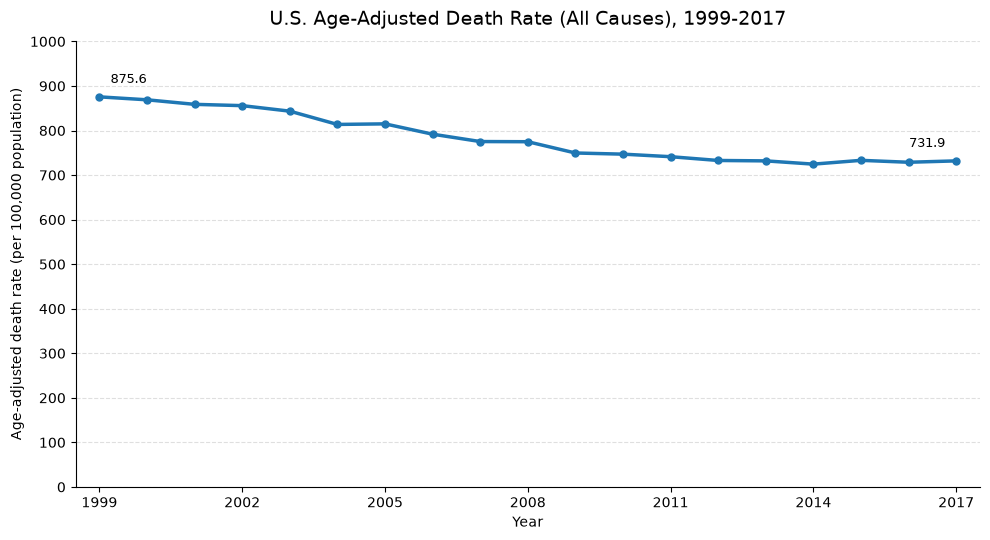

In [167]:
import matplotlib.pyplot as plt

US_sorted = US_aggregate.sort_values(by='Year')

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(
    US_sorted['Year'],
    US_sorted['Age-adjusted Death Rate'],
    color='#1f77b4',
    marker='o',
    linewidth=2.5,
    markersize=5,
)

ax.set_title('U.S. Age-Adjusted Death Rate (All Causes), 1999-2017', fontsize=14, pad=12)
ax.set_xlabel('Year')
ax.set_ylabel('Age-adjusted death rate (per 100,000 population)')
ax.set_xlim(1998.5, 2017.5)
ax.set_ylim(0, 1000)
ax.set_xticks(range(1999, 2018, 3))
ax.set_yticks(range(0, 1001, 100))
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

for index, offset, alignment in [(0, (8, 10), 'left'), (-1, (-8, 10), 'right')]:
    row = US_sorted.iloc[index]
    ax.annotate(
        f"{row['Age-adjusted Death Rate']:.1f}",
        xy=(row['Year'], row['Age-adjusted Death Rate']),
        xytext=offset,
        textcoords='offset points',
        ha=alignment,
        fontsize=9,
    )

fig.tight_layout()
fig.savefig("us_age_adjusted_death_rate.svg", format="svg", bbox_inches="tight")
plt.show()

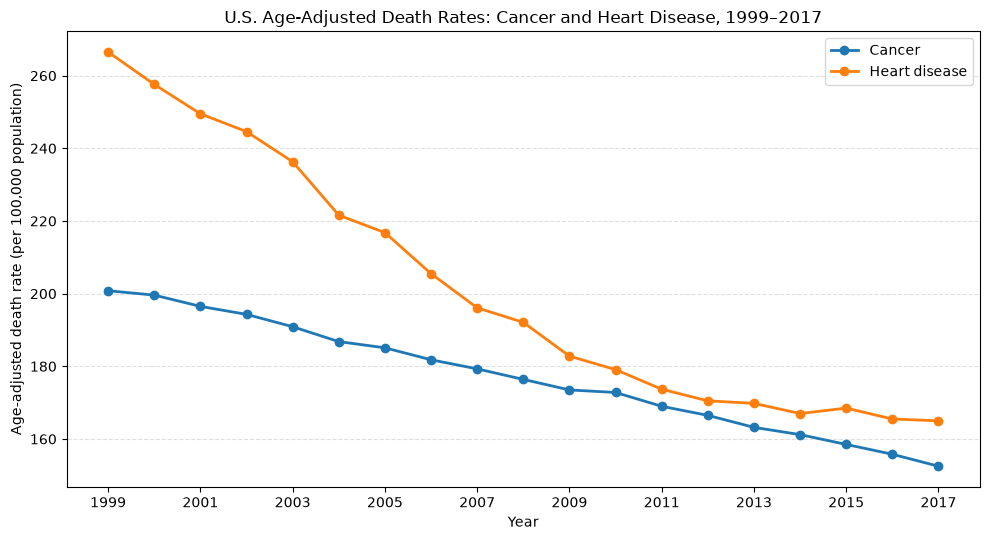

In [168]:
US_include_exclude_all = data[(data['State'] == 'United States') & (data['Cause Name'] != 'All causes')]
US_include_exclude_all[US_include_exclude_all['Year'] == 2017]

cancer = US_include_exclude_all[US_include_exclude_all['Cause Name'] == 'Cancer'].sort_values(by='Year')
cancer
heart = US_include_exclude_all[US_include_exclude_all['Cause Name'] == 'Heart disease'].sort_values(by='Year')
heart

#plot a line chart of cancer and heart disease age-adjusted death rates in the US from 1999 to 2017
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    cancer['Year'],
    cancer['Age-adjusted Death Rate'],
    marker='o',
    linewidth=2,
    label='Cancer',
)
ax.plot(
    heart['Year'],
    heart['Age-adjusted Death Rate'],
    marker='o',
    linewidth=2,
    label='Heart disease',
)

ax.set_title('U.S. Age-Adjusted Death Rates: Cancer and Heart Disease, 1999–2017')
ax.set_xlabel('Year')
ax.set_ylabel('Age-adjusted death rate (per 100,000 population)')
ax.set_xticks(range(1999, 2018, 2))
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend()
fig.tight_layout()
fig.savefig('cancer_heart_disease.svg', format='svg', bbox_inches='tight')
plt.show()


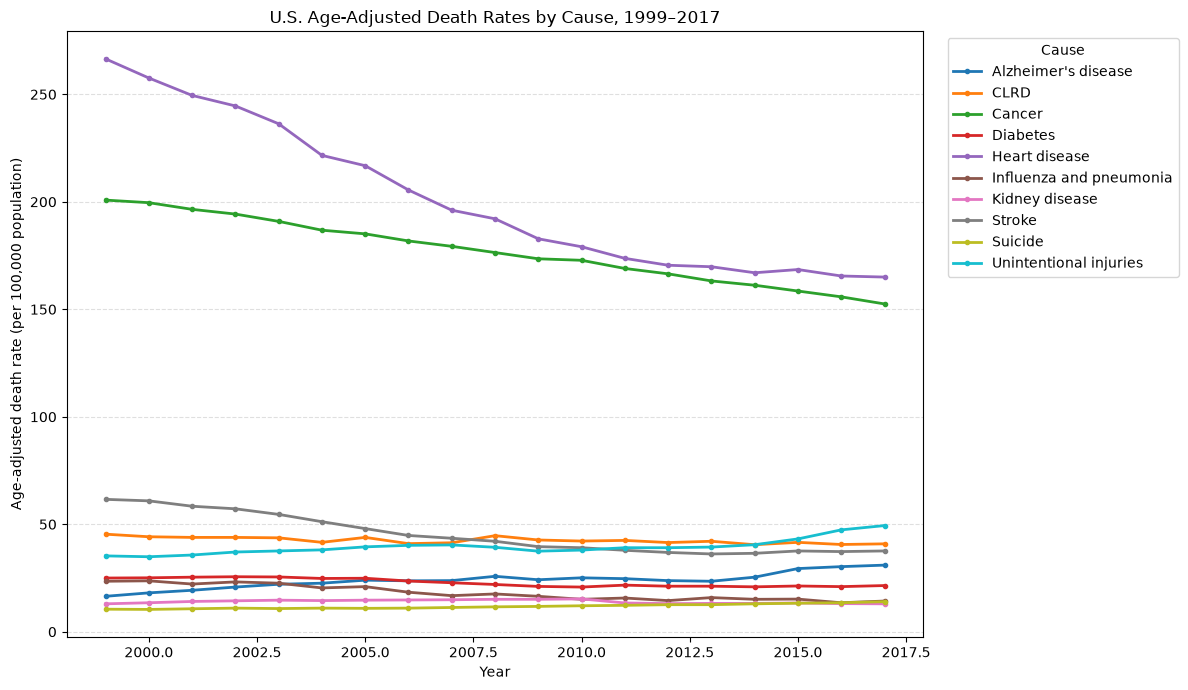

In [169]:
# Plot age-adjusted death rates for each cause in the United States
cause_rates = US_include_exclude_all.pivot(
    index='Year',
    columns='Cause Name',
    values='Age-adjusted Death Rate'
).sort_index()

fig, ax = plt.subplots(figsize=(12, 7))
cause_rates.plot(ax=ax, marker='o', linewidth=2, markersize=3)

ax.set_title('U.S. Age-Adjusted Death Rates by Cause, 1999–2017')
ax.set_xlabel('Year')
ax.set_ylabel('Age-adjusted death rate (per 100,000 population)')
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.legend(title='Cause', bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
fig.savefig('us_age_adjusted_death_rates_by_cause.svg', format='svg', bbox_inches='tight')
plt.show()

In [170]:
US_include_exclude_all.sort_values(by='Age-adjusted Death Rate',ascending=False).head()

,Year,113 Cause Name,Cause Name,State,Deaths,Age-adjusted Death Rate
9793,1999,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,United States,725192,266.50
9769,2000,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,United States,710760,257.60
9742,2001,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,United States,700142,249.50
9727,2002,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,United States,696947,244.60
9682,2003,"Diseases of heart (I00-I09,I11,I13,I20-I51)",Heart disease,United States,685089,236.30


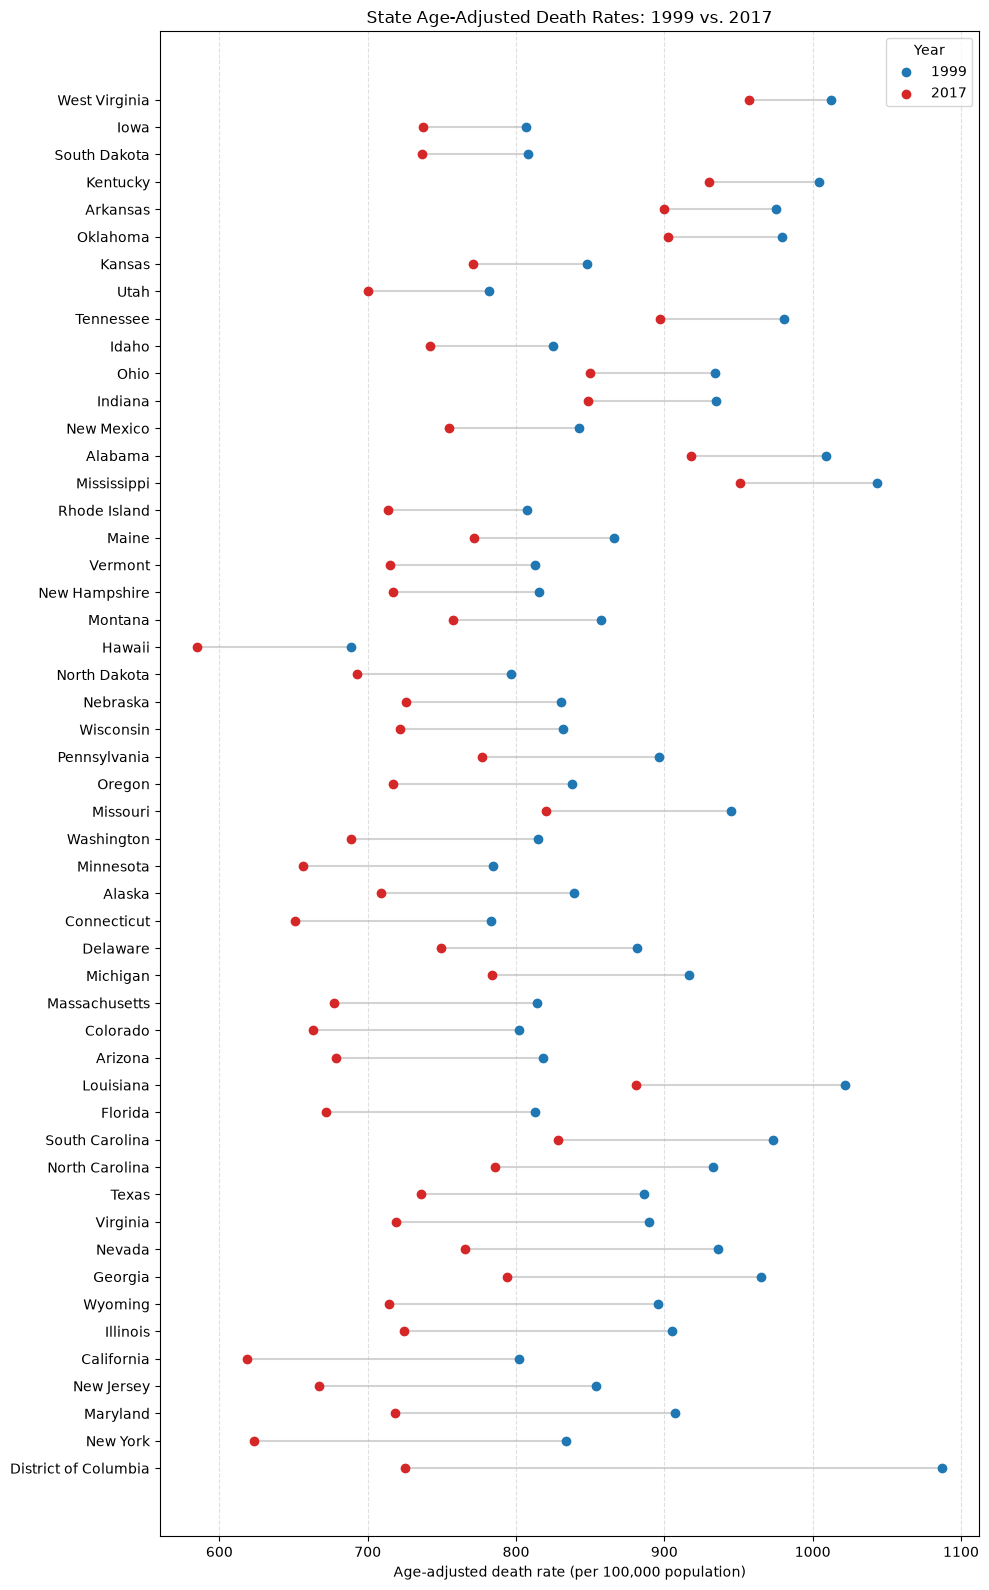

In [171]:
exclude_states_only_all = include_all[include_all['State'] != 'United States']
exclude_states_only_all.sort_values(by='Age-adjusted Death Rate',ascending=False)

all_state_first_last = exclude_states_only_all[exclude_states_only_all['Year'].isin([1999, 2017])].sort_values(by='Age-adjusted Death Rate',ascending=False)

rates_by_state = all_state_first_last.pivot(
    index='State',
    columns='Year',
    values='Age-adjusted Death Rate'
).dropna()

rates_by_state['Change'] = rates_by_state[2017] - rates_by_state[1999]
rates_by_state = rates_by_state.sort_values('Change')
positions = range(len(rates_by_state))

fig, ax = plt.subplots(figsize=(10, 16))

for position, (_, row) in zip(positions, rates_by_state.iterrows()):
    ax.plot(
        [row[1999], row[2017]],
        [position, position],
        color='lightgray',
        linewidth=1.5,
        zorder=1,
    )

ax.scatter(rates_by_state[1999], positions, label='1999', color='#1f77b4', zorder=2)
ax.scatter(rates_by_state[2017], positions, label='2017', color='#d62728', zorder=2)

ax.set_yticks(list(positions))
ax.set_yticklabels(rates_by_state.index)
ax.set_xlabel('Age-adjusted death rate (per 100,000 population)')
ax.set_title('State Age-Adjusted Death Rates: 1999 vs. 2017')
ax.grid(axis='x', linestyle='--', alpha=0.4)
ax.legend(title='Year')
fig.tight_layout()
fig.savefig('state_age_adjusted_death_rates.svg', format='svg', bbox_inches='tight')
plt.show()
